# Príprava dát: Threat Modeling and Risk Assessment

Notebook obsahuje kód aj dokumentáciu k časti **Príprava dát**: použitie datasetu (min. 1 000 záznamov), vyčistenie údajov, analýzu a 2 vizualizácie.

| | |
| --- | --- |
| **Vstup** | `data/raw/Global_Dataset.csv`, [CVE and CWE Mapping Dataset (2021)](https://huggingface.co/datasets/zefang-liu/cve-and-cwe-mapping-dataset), licencia CC BY-NC-SA 4.0 |
| **Výstup** | `data/processed/cve_clean.csv`, `figures/1_cve_podla_roka.png`, `figures/2_top_cwe.png` |
| **Spustenie** | `jupyter nbconvert --to notebook --execute --inplace priprava_dat.ipynb` alebo postupne vo VS Code |

Pojmy:

- **CVE** je jedna verejne známa zraniteľnosť.
- **CVSS** je skóre závažnosti od 0 do 10. Dataset obsahuje verzie 2 a 3, ktoré sa počítajú odlišne.
- **CWE** je typ slabiny, napríklad SQL injection.

## 1. Načítanie dát

Funkcia `load_raw` z `main.py` dataset v prípade potreby stiahne, overí jeho SHA-256 a textovú hodnotu `None` načíta ako chýbajúcu.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import FuncFormatter

from main import load_raw

pd.set_option("display.max_colwidth", 80)
PROCESSED_PATH = Path("data/processed/cve_clean.csv")
FIGURES_DIR = Path("figures")

raw = load_raw()
print(f"Záznamy: {len(raw):,}".replace(",", " "))
raw.head(3)

Záznamy: 169 566


,ID,CVE-ID,CVSS-V3,CVSS-V2,SEVERITY,DESCRIPTION,CWE-ID
0,1,CVE-1999-0001,NaN,5.0,MEDIUM,ip_input.c in BSD-derived TCP/IP implementations allows remote attackers to ...,CWE-20
1,2,CVE-1999-0002,NaN,10.0,HIGH,"Buffer overflow in NFS mountd gives root access to remote attackers, mostly ...",CWE-119
2,3,CVE-1999-0003,NaN,10.0,HIGH,Execute commands as root via buffer overflow in Tooltalk database server (rp...,NVD-CWE-Other


## 2. Kontrola kvality surových dát

Pred čistením zisťujeme, aké problémy dáta naozaj obsahujú. Každý krok čistenia v časti 3 vychádza z tejto kontroly.

In [2]:
year_raw = raw["CVE-ID"].str.extract(r"CVE-(\d{4})-", expand=False).astype(int)
quality = pd.Series({
    "Záznamy spolu": len(raw),
    "Unikátne CVE-ID": raw["CVE-ID"].nunique(),
    "Riadky s opakovaným CVE-ID": raw["CVE-ID"].duplicated().sum(),
    "Úplné duplikáty (bez stĺpca ID)": raw.drop(columns="ID").duplicated().sum(),
    "Chýba CVSS-V3": raw["CVSS-V3"].isna().sum(),
    "Chýba CVSS-V2": raw["CVSS-V2"].isna().sum(),
    "Chýba CVSS-V2 aj CVSS-V3": raw[["CVSS-V2", "CVSS-V3"]].isna().all(axis=1).sum(),
    "Chýba SEVERITY": raw["SEVERITY"].isna().sum(),
    "Zamietnuté záznamy (REJECT)": raw["DESCRIPTION"].str.contains(r"\*\*\s*REJECT", regex=True).sum(),
    "Spochybnené záznamy (DISPUTED)": raw["DESCRIPTION"].str.contains(r"\*\*\s*DISPUTED", regex=True).sum(),
    "CWE je zástupná hodnota NVD-CWE-*": raw["CWE-ID"].str.startswith("NVD-CWE").sum(),
    "Neplatný formát CVE-ID": (~raw["CVE-ID"].str.fullmatch(r"CVE-\d{4}-\d{4,}")).sum(),
    "CVSS mimo rozsahu 0 až 10": ((raw[["CVSS-V2", "CVSS-V3"]] < 0) | (raw[["CVSS-V2", "CVSS-V3"]] > 10)).any(axis=1).sum(),
}, name="počet")
display(quality.to_frame())

print("Podiel záznamov s CVSS v3 podľa roka v CVE-ID:")
print(raw["CVSS-V3"].notna().groupby(year_raw).mean().round(2).to_dict())

,počet
Záznamy spolu,169566
Unikátne CVE-ID,166337
Riadky s opakovaným CVE-ID,3229
Úplné duplikáty (bez stĺpca ID),64
Chýba CVSS-V3,74007
Chýba CVSS-V2,105
Chýba CVSS-V2 aj CVSS-V3,86
Chýba SEVERITY,86
Zamietnuté záznamy (REJECT),32
Spochybnené záznamy (DISPUTED),916


Podiel záznamov s CVSS v3 podľa roka v CVE-ID:
{1999: 0.0, 2000: 0.0, 2001: 0.0, 2002: 0.0, 2003: 0.0, 2004: 0.0, 2005: 0.0, 2006: 0.0, 2007: 0.0, 2008: 0.0, 2009: 0.01, 2010: 0.03, 2011: 0.06, 2012: 0.06, 2013: 0.09, 2014: 0.13, 2015: 0.32, 2016: 0.98, 2017: 1.0, 2018: 1.0, 2019: 1.0, 2020: 1.0, 2021: 1.0}


In [3]:
# Líšia sa riadky s rovnakým CVE-ID aj v niečom inom než v CWE?
repeated = raw[raw["CVE-ID"].duplicated(keep=False)]
differences = repeated.groupby("CVE-ID")[["CVSS-V3", "CVSS-V2", "SEVERITY", "DESCRIPTION"]].nunique().max()
print("Najväčší počet rôznych hodnôt v rámci jedného CVE-ID:")
print(differences)

# Ako vznikol stĺpec SEVERITY?
with_v3 = raw["CVSS-V3"].notna()
print("\nSEVERITY pri záznamoch bez CVSS v3:", raw.loc[~with_v3, "SEVERITY"].value_counts().to_dict())
print("SEVERITY pri záznamoch s CVSS v3:", raw.loc[with_v3, "SEVERITY"].value_counts().to_dict())

Najväčší počet rôznych hodnôt v rámci jedného CVE-ID:
CVSS-V3        1
CVSS-V2        1
SEVERITY       1
DESCRIPTION    1
dtype: int64

SEVERITY pri záznamoch bez CVSS v3: {'MEDIUM': 38548, 'HIGH': 29983, 'LOW': 5390}
SEVERITY pri záznamoch s CVSS v3: {'HIGH': 41634, 'MEDIUM': 37912, 'CRITICAL': 14198, 'LOW': 1815}


**Zistenia:**

- Rovnaké `CVE-ID` sa opakuje preto, že zraniteľnosť môže mať viac typov slabiny. Ostatné stĺpce sú v rámci jedného CVE zhodné.
- CVSS v3 sa začína vo väčšom rozsahu používať až pri CVE z roku 2016, staršie záznamy ho takmer nemajú. Chýbanie teda nie je náhodné a hodnoty sa nedajú rozumne doplniť z priemeru.
- `SEVERITY` mieša dve stupnice: hodnota `CRITICAL` existuje len pri CVSS v3. Priame porovnanie cez roky by bolo skreslené.

## 3. Čistenie dát

| Krok | Postup | Dôvod |
| --- | --- | --- |
| 1 | Odstrániť stĺpec `ID`, premenovať stĺpce, orezať medzery v popise | `ID` je len poradie riadku, jednotné názvy sa lepšie používajú v kóde |
| 2 | Odstrániť úplné duplikáty | Nenesú žiadnu novú informáciu |
| 3 | Odstrániť záznamy `REJECT` | Podľa registra CVE nejde o platné zraniteľnosti |
| 4 | Odstrániť záznamy bez CVSS v2 aj v3 | Bez skóre sa riziko nedá hodnotiť |
| 5 | Zlúčiť riadky na jeden riadok za CVE, typy CWE spojiť do `cwe_ids` | Jedna zraniteľnosť sa nesmie započítať viackrát |
| 6 | Zástupné hodnoty `NVD-CWE-*` považovať za neznámy typ | Neoznačujú konkrétnu slabinu |
| 7 | Doplniť odvodené stĺpce | Rok, jednotná závažnosť a príznaky pre analýzu |

Chýbajúce CVSS **nedopĺňame** odhadom, pretože v2 a v3 používajú odlišné stupnice a chýbanie súvisí s vekom záznamu. Záznamy `DISPUTED` ponechávame, označíme ich však príznakom, lebo spochybnené neznamená neplatné.

In [4]:
cleaning_log = []

def log_step(name, frame):
    cleaning_log.append({
        "krok": name,
        "riadky": len(frame),
        "unikátne CVE": frame["cve_id"].nunique(),
    })

# Krok 1: štruktúra a formát
df = raw.drop(columns="ID").rename(columns={
    "CVE-ID": "cve_id",
    "CVSS-V3": "cvss_v3",
    "CVSS-V2": "cvss_v2",
    "SEVERITY": "severity_original",
    "DESCRIPTION": "description",
    "CWE-ID": "cwe_id",
})
df["description"] = df["description"].str.strip()
log_step("Surové dáta", df)

# Krok 2: úplné duplikáty
df = df.drop_duplicates()
log_step("Bez úplných duplikátov", df)

# Krok 3: zamietnuté záznamy
df = df[~df["description"].str.contains(r"\*\*\s*REJECT", regex=True)]
log_step("Bez záznamov REJECT", df)

# Krok 4: záznamy bez skóre
df = df.dropna(subset=["cvss_v2", "cvss_v3"], how="all")
log_step("Bez záznamov bez skóre", df)

In [5]:
# Kroky 5 a 6: jeden riadok za CVE, iba konkrétne typy CWE
def join_specific_cwes(values):
    specific = {value for value in values if value.startswith("CWE-")}
    ordered = sorted(specific, key=lambda value: int(value.removeprefix("CWE-")))
    return ";".join(ordered) if ordered else None

cves = (
    df.groupby("cve_id", sort=False)
    .agg(
        cvss_v3=("cvss_v3", "first"),
        cvss_v2=("cvss_v2", "first"),
        severity_original=("severity_original", "first"),
        description=("description", "first"),
        cwe_ids=("cwe_id", join_specific_cwes),
    )
    .reset_index()
)
log_step("Jeden riadok za CVE", cves)

# Krok 7: odvodené stĺpce
SEVERITY_V2 = ["LOW", "MEDIUM", "HIGH"]
SEVERITY_V3 = ["LOW", "MEDIUM", "HIGH", "CRITICAL"]

cves["year"] = cves["cve_id"].str.extract(r"CVE-(\d{4})-", expand=False).astype(int)
cves["severity_v2"] = pd.cut(cves["cvss_v2"], [0, 4, 7, 10.01], right=False, labels=SEVERITY_V2)
cves["severity_v3"] = pd.cut(cves["cvss_v3"], [0, 4, 7, 9, 10.01], right=False, labels=SEVERITY_V3)
cves["has_cvss_v3"] = cves["cvss_v3"].notna()
cves["has_known_cwe"] = cves["cwe_ids"].notna()
cves["is_disputed"] = cves["description"].str.contains(r"\*\*\s*DISPUTED", regex=True)

pd.DataFrame(cleaning_log)

,krok,riadky,unikátne CVE
0,Surové dáta,169566,166337
1,Bez úplných duplikátov,169502,166337
2,Bez záznamov REJECT,169470,166309
3,Bez záznamov bez skóre,169416,166256
4,Jeden riadok za CVE,166256,166256


## 4. Overenie vyčistených dát

Tvrdenia nižšie zlyhajú, ak by čistenie porušilo niektoré z očakávaní. Posledná kontrola potvrdzuje, ako vznikol pôvodný stĺpec `SEVERITY`.

In [6]:
assert cves["cve_id"].is_unique
assert not cves["description"].str.contains(r"\*\*\s*REJECT", regex=True).any()
assert cves[["cvss_v2", "cvss_v3"]].notna().any(axis=1).all()
assert cves["cvss_v2"].dropna().between(0, 10).all()
assert cves["cvss_v3"].dropna().between(0, 10).all()
assert cves["cwe_ids"].dropna().str.fullmatch(r"CWE-\d+(;CWE-\d+)*").all()
assert len(cves) >= 1_000

# SEVERITY je pásmo CVSS v3, a ak v3 chýba, pásmo CVSS v2
expected = cves["severity_v3"].astype("string").fillna(cves["severity_v2"].astype("string"))
assert expected.eq(cves["severity_original"].astype("string")).all()

print(f"Kontroly prešli. Výsledok: {len(cves)} záznamov, {cves.shape[1]} stĺpcov.")
display(cves.isna().sum().to_frame("chýbajúce hodnoty"))
cves.head(3)

Kontroly prešli. Výsledok: 166256 záznamov, 12 stĺpcov.


,chýbajúce hodnoty
cve_id,0
cvss_v3,73363
cvss_v2,18
severity_original,0
description,0
cwe_ids,45099
year,0
severity_v2,18
severity_v3,73363
has_cvss_v3,0


,cve_id,cvss_v3,cvss_v2,severity_original,description,cwe_ids,year,severity_v2,severity_v3,has_cvss_v3,has_known_cwe,is_disputed
0,CVE-1999-0001,NaN,5.0,MEDIUM,ip_input.c in BSD-derived TCP/IP implementations allows remote attackers to ...,CWE-20,1999,MEDIUM,NaN,False,True,False
1,CVE-1999-0002,NaN,10.0,HIGH,"Buffer overflow in NFS mountd gives root access to remote attackers, mostly ...",CWE-119,1999,HIGH,NaN,False,True,False
2,CVE-1999-0003,NaN,10.0,HIGH,Execute commands as root via buffer overflow in Tooltalk database server (rp...,NaN,1999,HIGH,NaN,False,False,False


## 5. Analýza

### 5.1 Závažnosť

Na porovnanie celého obdobia používame **CVSS v2**, lebo ho má takmer každý záznam. CVSS v3 má zmysel najmä pri novších CVE.

In [7]:
display(cves[["cvss_v2", "cvss_v3"]].describe().round(2))

severity_summary = pd.DataFrame({
    "počet (v2)": cves["severity_v2"].value_counts().reindex(SEVERITY_V2),
    "podiel % (v2)": cves["severity_v2"].value_counts(normalize=True).reindex(SEVERITY_V2).mul(100).round(1),
})
display(severity_summary)

both = cves.dropna(subset=["cvss_v2", "cvss_v3"])
print(f"Záznamy s oboma verziami CVSS: {len(both):,}".replace(",", " "))
print(f"Priemer v2: {both['cvss_v2'].mean():.2f}, priemer v3: {both['cvss_v3'].mean():.2f}")
print(f"Pearsonova korelácia v2 a v3: {both['cvss_v2'].corr(both['cvss_v3']):.2f}")
pd.crosstab(both["severity_v2"], both["severity_v3"], margins=True, margins_name="spolu")

,cvss_v2,cvss_v3
count,166238.00,92893.00
mean,5.92,7.21
std,1.99,1.65
min,0.00,1.80
25%,4.30,6.10
50%,5.40,7.50
75%,7.50,8.80
max,10.00,10.00


,počet (v2),podiel % (v2)
severity_v2,,
LOW,17034,10.2
MEDIUM,95766,57.6
HIGH,53438,32.1


Záznamy s oboma verziami CVSS: 92 875
Priemer v2: 5.67, priemer v3: 7.21
Pearsonova korelácia v2 a v3: 0.75


severity_v3,LOW,MEDIUM,HIGH,CRITICAL,spolu
severity_v2,,,,,
LOW,1083,9945,642,8,11678
MEDIUM,684,26094,28801,1876,57455
HIGH,0,1100,10768,11874,23742
spolu,1767,37139,40211,13758,92875


### 5.2 Vývoj v čase

Rok pochádza z `CVE-ID`, teda ide o rok pridelenia identifikátora, nie nevyhnutne rok zverejnenia.

In [8]:
by_year = (
    cves.dropna(subset=["severity_v2"])
    .groupby(["year", "severity_v2"], observed=False)
    .size()
    .unstack()[SEVERITY_V2]
)
year_table = by_year.assign(
    spolu=by_year.sum(axis=1),
    **{"HIGH %": (by_year["HIGH"] / by_year.sum(axis=1)).mul(100).round(1)},
)
year_table

severity_v2,LOW,MEDIUM,HIGH,spolu,HIGH %
year,,,,,
1999,165,568,808,1541,52.4
2000,128,581,528,1237,42.7
2001,174,638,726,1538,47.2
2002,162,1111,1083,2356,46.0
2003,96,712,692,1500,46.1
2004,242,1335,1067,2644,40.4
2005,416,2341,1866,4623,40.4
2006,527,3511,2953,6991,42.2
2007,233,3098,3123,6454,48.4


### 5.3 Typy slabín (CWE)

CVE s viacerými typmi CWE sa započíta pri každom z nich. Záznamy bez konkrétneho CWE sú z rebríčka vylúčené.

In [9]:
known_share = cves["has_known_cwe"].mean() * 100
print(f"Záznamy s konkrétnym CWE: {known_share:.1f} %, počet rôznych CWE: {cves['cwe_ids'].dropna().str.split(';').explode().nunique()}")

CWE_NAMES = {
    "CWE-79": "Cross-site scripting",
    "CWE-119": "Chyby práce s pamäťou",
    "CWE-20": "Nesprávna kontrola vstupu",
    "CWE-89": "SQL injection",
    "CWE-200": "Únik informácií",
    "CWE-264": "Oprávnenia a prístup",
    "CWE-22": "Path traversal",
    "CWE-125": "Čítanie mimo hraníc",
    "CWE-352": "Cross-site request forgery",
    "CWE-787": "Zápis mimo hraníc",
    "CWE-399": "Správa zdrojov",
    "CWE-416": "Use after free",
    "CWE-94": "Vkladanie kódu",
}

cwe_long = cves.assign(cwe=cves["cwe_ids"].str.split(";")).explode("cwe").dropna(subset=["cwe"])
top_cwe = (
    cwe_long.groupby("cwe")
    .agg(
        pocet=("cve_id", "size"),
        priemer_cvss_v2=("cvss_v2", "mean"),
        podiel_high_pct=("severity_v2", lambda s: (s == "HIGH").mean() * 100),
    )
    .sort_values("pocet", ascending=False)
    .head(10)
    .round(1)
)
top_cwe.insert(0, "nazov", top_cwe.index.map(CWE_NAMES))
assert top_cwe["nazov"].notna().all()
top_cwe

Záznamy s konkrétnym CWE: 72.9 %, počet rôznych CWE: 304


,nazov,pocet,priemer_cvss_v2,podiel_high_pct
cwe,,,,
CWE-79,Cross-site scripting,17411,4.1,0.3
CWE-119,Chyby práce s pamäťou,11485,7.6,61.2
CWE-20,Nesprávna kontrola vstupu,8566,6.0,32.5
CWE-89,SQL injection,6991,7.2,71.9
CWE-200,Únik informácií,6748,4.3,3.4
CWE-264,Oprávnenia a prístup,5320,6.2,38.3
CWE-787,Zápis mimo hraníc,5204,6.9,44.0
CWE-22,Path traversal,4114,5.9,23.9
CWE-125,Čítanie mimo hraníc,3857,5.2,14.2


## 6. Vizualizácie

Obidva grafy používajú CVSS v2, aby boli hodnoty porovnateľné v celom období. Do prvého grafu sa nezapočítava 18 záznamov, ktoré CVSS v2 nemajú. Presné hodnoty sú v tabuľkách v časti 5.

In [10]:
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"
BLUE = "#2a78d6"
SEVERITY_COLORS = {"LOW": "#86b6ef", "MEDIUM": "#2a78d6", "HIGH": "#104281"}

plt.rcParams.update({
    "font.family": ["Segoe UI", "DejaVu Sans"],
    "font.size": 10,
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": AXIS,
    "axes.labelcolor": INK_SECONDARY,
    "axes.titlecolor": INK,
    "text.color": INK,
    "xtick.color": INK_SECONDARY,
    "ytick.color": INK_SECONDARY,
    "savefig.dpi": 160,
    "savefig.bbox": "tight",
    "savefig.facecolor": SURFACE,
})

FIGURES_DIR.mkdir(exist_ok=True)
thousands = FuncFormatter(lambda value, _: f"{value:,.0f}".replace(",", " "))

def clean_axes(ax, grid_axis):
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)

### Vizualizácia 1: počet zraniteľností podľa roka a závažnosti

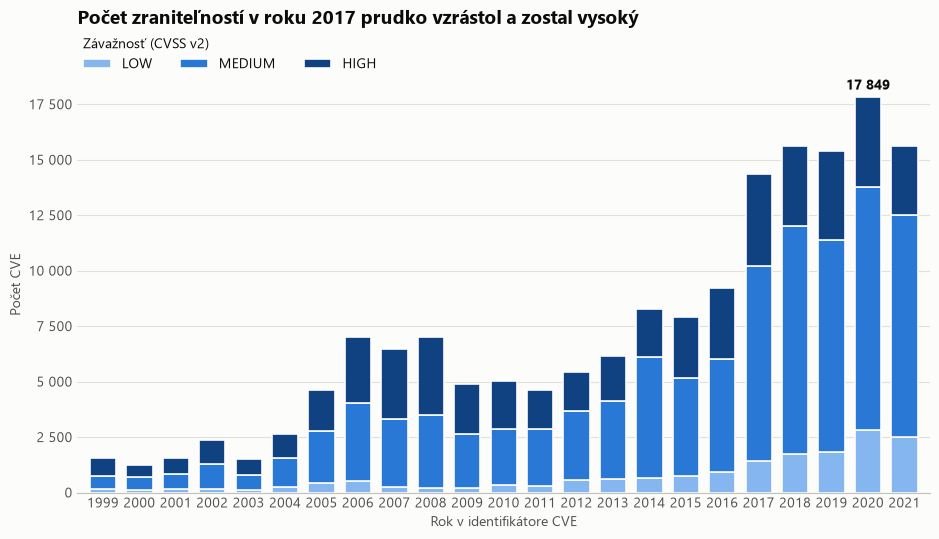

In [11]:
fig, ax = plt.subplots(figsize=(11, 5.4))
bottom = np.zeros(len(by_year))

for severity in SEVERITY_V2:
    ax.bar(by_year.index, by_year[severity], bottom=bottom, width=0.72,
           color=SEVERITY_COLORS[severity], edgecolor=SURFACE, linewidth=1.2, label=severity)
    bottom += by_year[severity].to_numpy()

peak_year = by_year.sum(axis=1).idxmax()
peak_value = by_year.loc[peak_year].sum()
ax.annotate(f"{peak_value:,.0f}".replace(",", " "), (peak_year, peak_value),
            xytext=(0, 5), textcoords="offset points", ha="center", color=INK, fontweight="bold")

clean_axes(ax, "y")
ax.yaxis.set_major_formatter(thousands)
ax.set_xticks(by_year.index)
ax.set_xlim(by_year.index.min() - 0.7, by_year.index.max() + 0.7)
ax.set_ylabel("Počet CVE")
ax.set_xlabel("Rok v identifikátore CVE")
ax.set_title("Počet zraniteľností v roku 2017 prudko vzrástol a zostal vysoký",
             loc="left", fontsize=14, fontweight="bold", pad=38)
ax.legend(title="Závažnosť (CVSS v2)", ncols=3, frameon=False, loc="lower left",
          bbox_to_anchor=(0, 1.0), alignment="left", borderaxespad=0)

fig.savefig(FIGURES_DIR / "1_cve_podla_roka.png")
plt.show()

### Vizualizácia 2: najčastejšie typy slabín a ich závažnosť

Hodnotenie rizika spája výskyt a závažnosť, preto sú obe veličiny vedľa seba, každá na vlastnej osi.

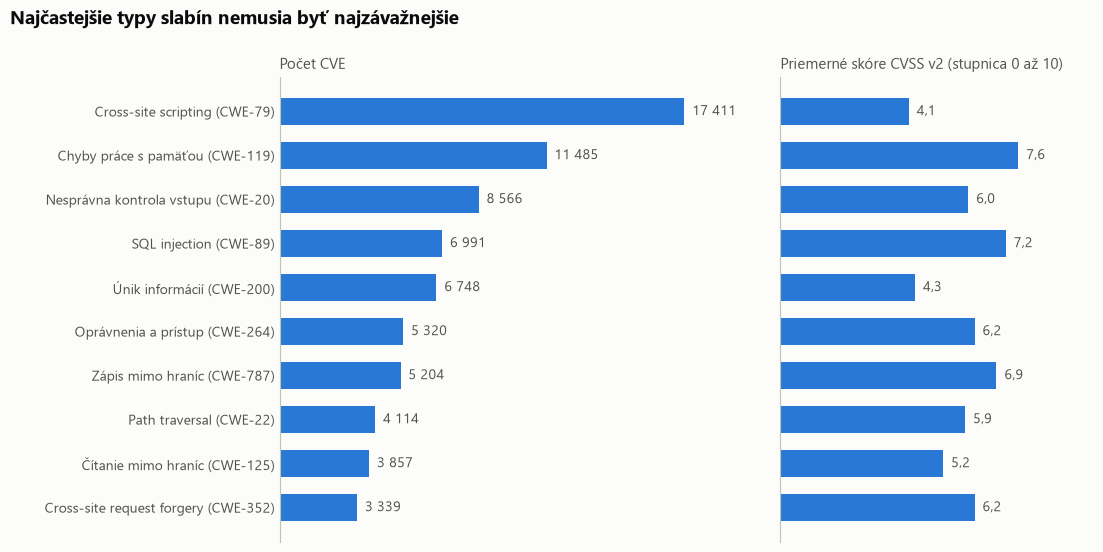

In [12]:
plot_data = top_cwe.iloc[::-1]
labels = [f"{name} ({cwe})" for cwe, name in plot_data["nazov"].items()]

fig, (ax_count, ax_score) = plt.subplots(
    1, 2, figsize=(11, 5.6), sharey=True, gridspec_kw={"width_ratios": [1.5, 1], "wspace": 0.08}
)

ax_count.barh(labels, plot_data["pocet"], height=0.6, color=BLUE)
ax_score.barh(labels, plot_data["priemer_cvss_v2"], height=0.6, color=BLUE)

for y, value in enumerate(plot_data["pocet"]):
    ax_count.text(value, y, f"  {value:,.0f}".replace(",", " "), va="center", color=INK_SECONDARY)
for y, value in enumerate(plot_data["priemer_cvss_v2"]):
    ax_score.text(value, y, f"  {value:.1f}".replace(".", ","), va="center", color=INK_SECONDARY)

# Každý stĺpec má priamy popis hodnoty, os x a mriežka by boli nadbytočné
for ax, title in ((ax_count, "Počet CVE"), (ax_score, "Priemerné skóre CVSS v2 (stupnica 0 až 10)")):
    ax.spines[["top", "right", "bottom"]].set_visible(False)
    ax.tick_params(length=0)
    ax.set_xticks([])
    ax.set_title(title, loc="left", fontsize=11, color=INK_SECONDARY)

ax_count.set_xlim(0, plot_data["pocet"].max() * 1.16)
ax_score.set_xlim(0, 10)
fig.subplots_adjust(left=0.25, right=0.99, top=0.86, bottom=0.03)
fig.suptitle("Najčastejšie typy slabín nemusia byť najzávažnejšie",
             x=0.005, y=0.98, ha="left", fontsize=14, fontweight="bold")

fig.savefig(FIGURES_DIR / "2_top_cwe.png")
plt.show()

## 7. Uloženie výsledku

Vyčistené dáta sa ukladajú do `data/processed/`, ktorý git ignoruje.

In [13]:
PROCESSED_PATH.parent.mkdir(parents=True, exist_ok=True)
cves.to_csv(PROCESSED_PATH, index=False, encoding="utf-8")

check = pd.read_csv(PROCESSED_PATH)
assert len(check) == len(cves)
print(f"Uložené: {PROCESSED_PATH}, {len(check)} záznamov")

Uložené: data\processed\cve_clean.csv, 166256 záznamov


## 8. Zhrnutie

**Čistenie.** Zo 169 566 riadkov vzniklo 166 256 unikátnych zraniteľností:

| Úprava | Odstránené riadky |
| --- | ---: |
| Úplné duplikáty | 64 |
| Zamietnuté záznamy `REJECT` | 32 |
| Záznamy bez skóre CVSS | 54 |
| Zlúčenie viacerých CWE do jedného riadku za CVE | 3 160 |

**Zistenia z analýzy:**

- Podľa CVSS v2 je 10,2 % zraniteľností `LOW`, 57,6 % `MEDIUM` a 32,1 % `HIGH`.
- Počet CVE vzrástol z 9 213 v roku 2016 na 14 372 v roku 2017, teda o 56 %. Maximum je 17 849 v roku 2020.
- Podiel `HIGH` podľa CVSS v2 klesol z 52,4 % v roku 1999 na 19,8 % v roku 2021.
- Stupnice CVSS v2 a v3 nie sú zameniteľné. Pri 92 875 záznamoch s oboma verziami je priemer v2 5,67 a v3 7,21, korelácia je 0,75. Do pásma `HIGH` patrí podľa v2 25,6 % z nich, kým do `HIGH` alebo `CRITICAL` podľa v3 58,1 %.
- Najčastejší typ nie je najzávažnejší. Cross-site scripting má 17 411 CVE, no priemerné skóre len 4,1. Chyby práce s pamäťou majú 11 485 CVE a priemer 7,6, SQL injection 6 991 CVE a priemer 7,2.

**Obmedzenia:**

- Dáta končia rokom 2021 a tento rok nemusí byť úplný.
- Rok pochádza z identifikátora CVE, nemusí sa zhodovať s rokom zverejnenia.
- CVSS vyjadruje závažnosť, nie pravdepodobnosť skutočného zneužitia.
- Konkrétny typ CWE má 72,9 % záznamov, zvyšok je z rebríčka vylúčený.
- Niektoré typy CWE sa prekrývajú. CWE-787 a CWE-125 sú podtypy CWE-119, takže rebríček neporovnáva úplne oddelené skupiny.